In [53]:
from pdf2image import convert_from_path
from transformers import AutoModelForObjectDetection, AutoImageProcessor
from PIL import Image
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pdf2image import convert_from_path
from dotenv import load_dotenv
import cv2
import numpy as np
import yaml
from fastapi.datastructures import UploadFile
import json
from pypdf import PdfReader, PdfWriter
import io
from pdf2image import convert_from_bytes
import pandas as pd

load_dotenv()

images = convert_from_path("/home/advait/expense-tracker/statement_unlocked.pdf")

In [54]:
print(type(images))
print(len(images))

print(type(images[0]))
print(images[0].size)

<class 'list'>
18
<class 'PIL.PpmImagePlugin.PpmImageFile'>
(1653, 2339)


In [55]:
_det_processor = None
_det_model = None
_struct_processor = None
_struct_model = None

def ensure_models_loaded():
    global _det_processor, _det_model
    global _struct_processor, _struct_model

    if _det_model is None:
        _det_processor = AutoImageProcessor.from_pretrained(
            "microsoft/table-transformer-detection"
        )
        _det_model = AutoModelForObjectDetection.from_pretrained(
            "microsoft/table-transformer-detection"
        )
        _det_model.eval()

    if _struct_model is None:
        _struct_processor = AutoImageProcessor.from_pretrained(
            "microsoft/table-transformer-structure-recognition"
        )
        _struct_model = AutoModelForObjectDetection.from_pretrained(
            "microsoft/table-transformer-structure-recognition"
        )
        _struct_model.eval()

    return (
        _det_processor,
        _det_model,
        _struct_processor,
        _struct_model,
    )

In [56]:
ensure_models_loaded()

table_det_processor = _det_processor
table_det_model = _det_model

table_struct_processor = _struct_processor
table_struct_model = _struct_model

image_entries = images

table_det_outputs = []
pages = images

inputs = table_det_processor(
    images=pages,
    return_tensors="pt"
)

with torch.inference_mode():
    outputs = table_det_model(**inputs)

target_sizes = torch.tensor([
    page.size[::-1]
    for page in pages
])

det_results = table_det_processor.post_process_object_detection(
    outputs,
    threshold=0.7,
    target_sizes=target_sizes
)

padding = 40

for i, doc in enumerate(table_det_outputs):
    corresponding_statement_images = image_entries[i]
    corresponding_table_detection_results = table_det_outputs[i]

    for j, img in enumerate(corresponding_statement_images['inputs']):
        x1, y1, x2, y2 = map(int, corresponding_table_detection_results['boxes'][j].tolist())

Loading weights: 100%|██████████| 367/367 [00:00<00:00, 4373.05it/s]
[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-detection
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 5986.99it/s]
[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-structure-recognition
Key                                       

In [57]:
len(det_results)

18

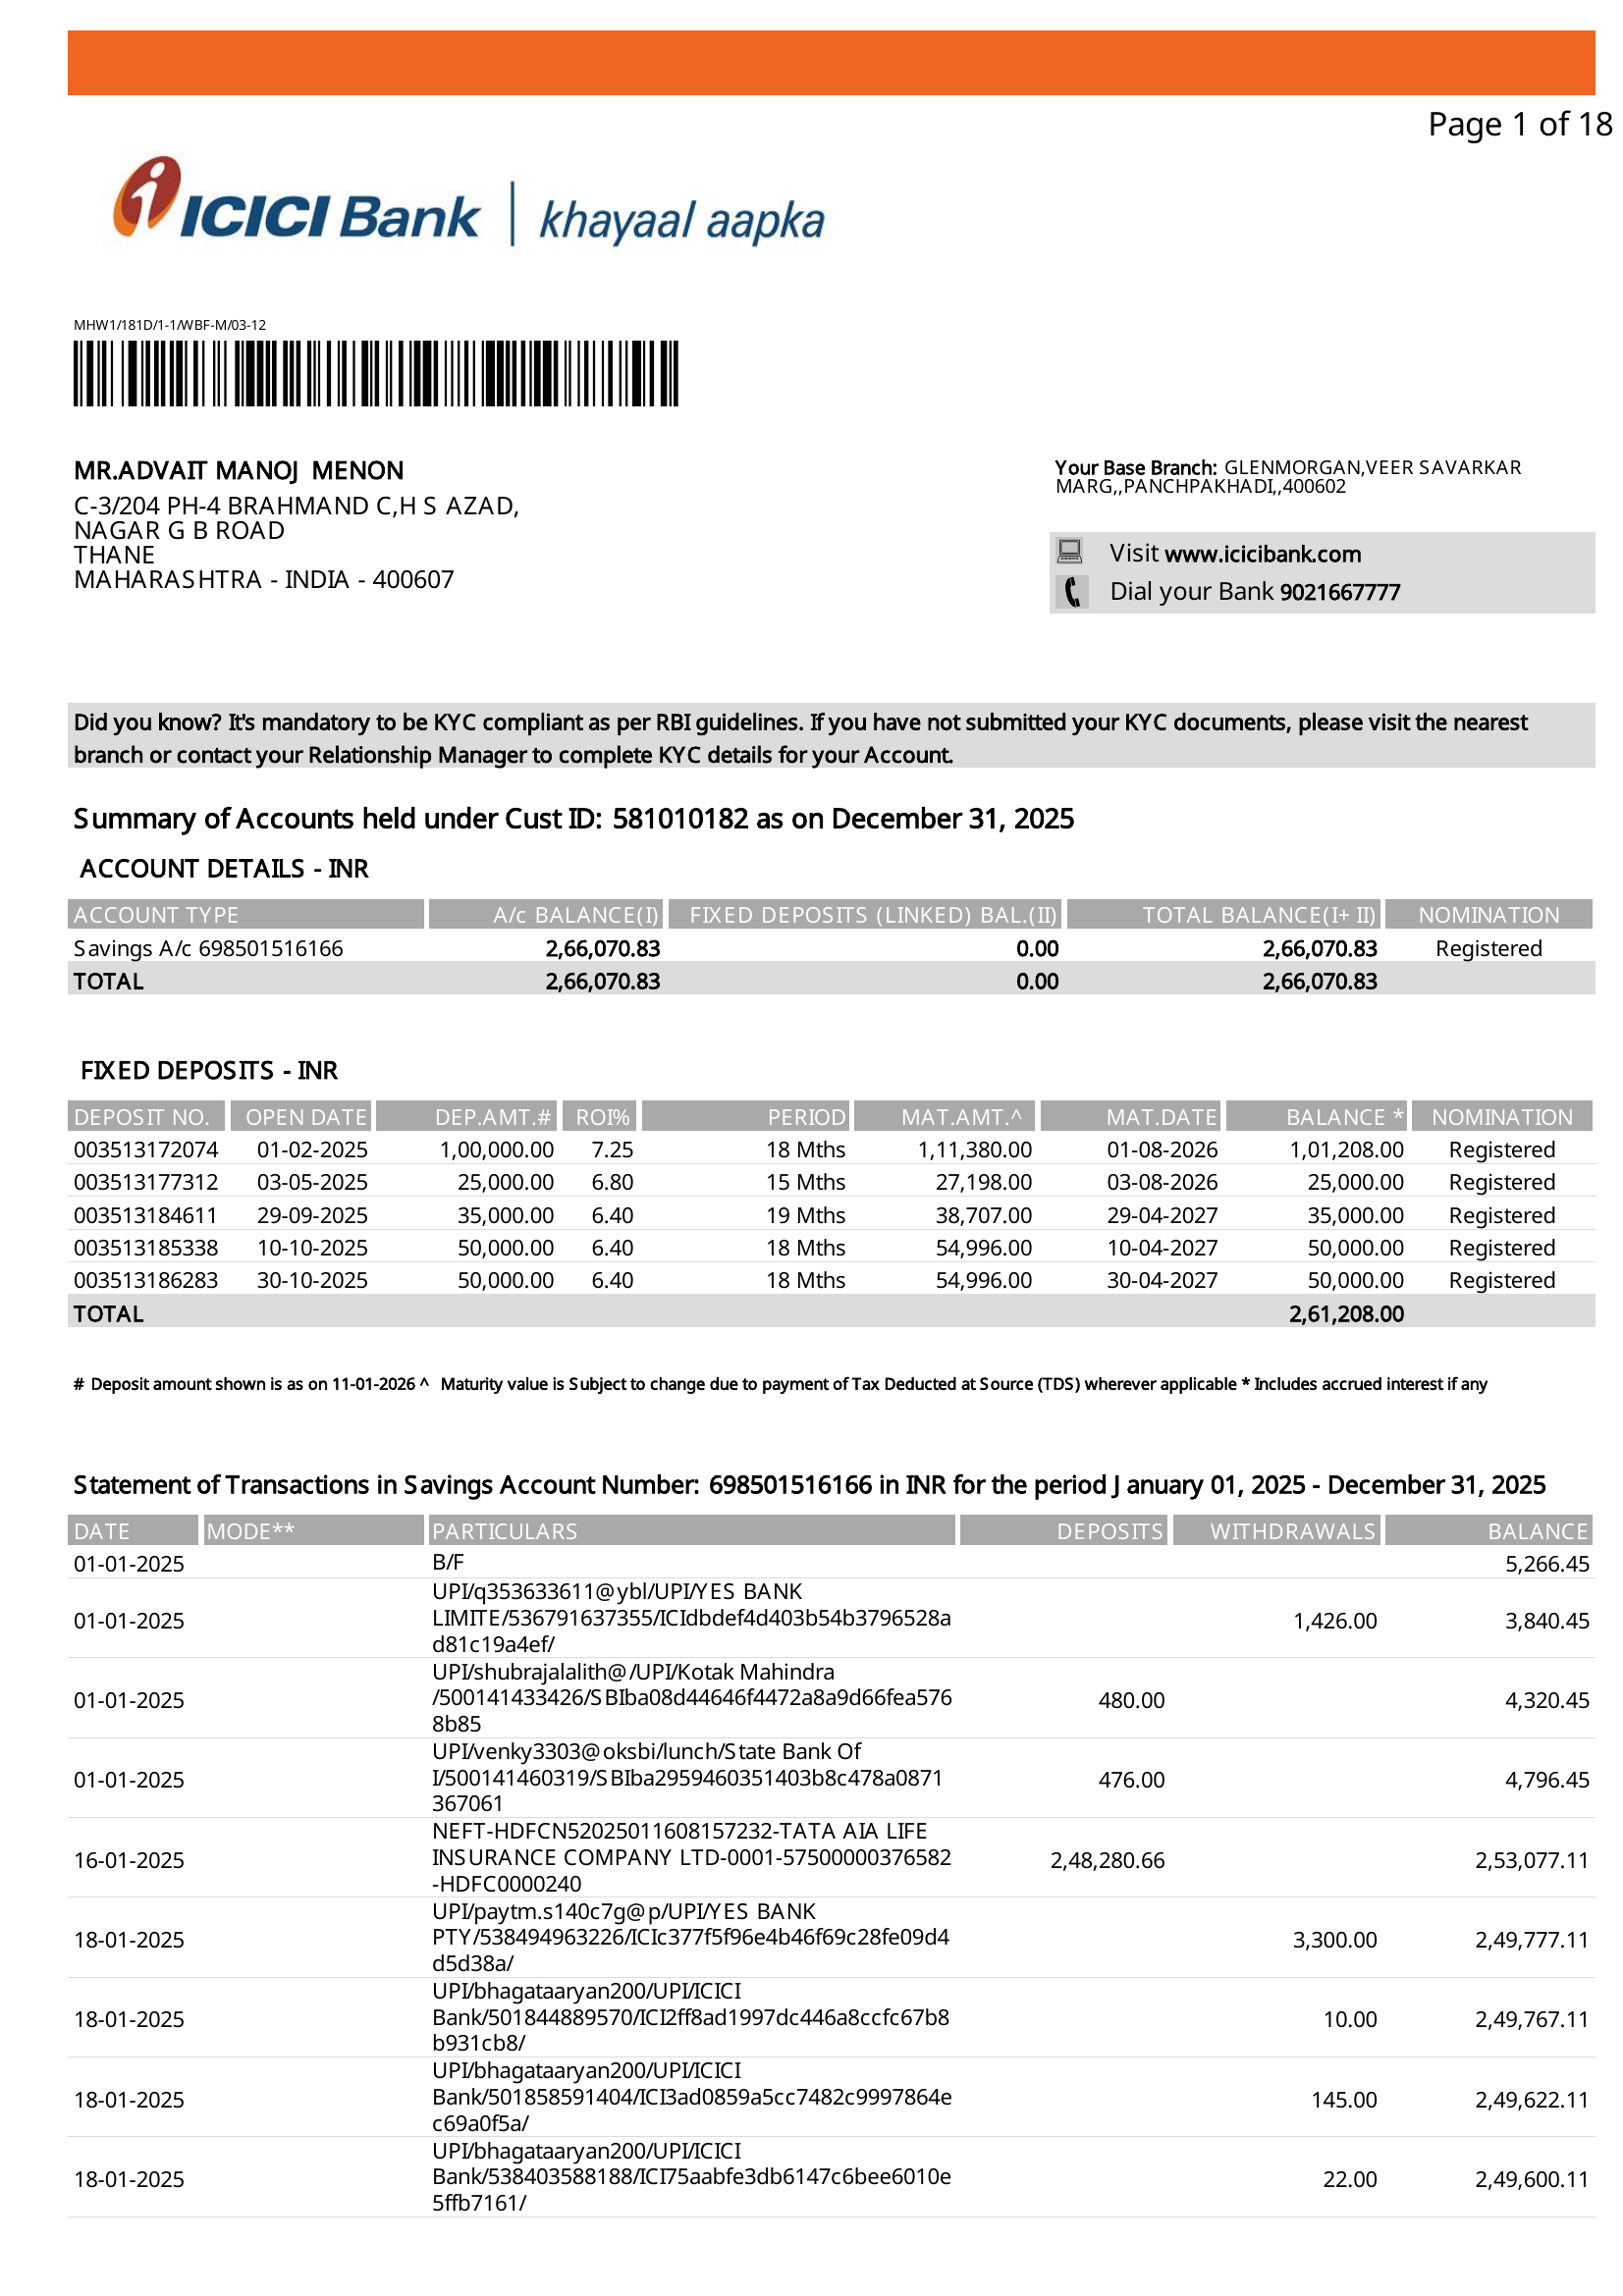

In [58]:
pages[0]

In [59]:
len(det_results[0]['boxes'])

2

In [60]:
x1, y1, x2, y2 = map(int, det_results[0]['boxes'][1].tolist())
# x1, y1, x2, y2 = map(sum, det_results[0]['boxes'][1].tolist())

In [61]:
len(det_results[1]['boxes'])

1

In [62]:
map(int, [x1, y1, x2, y2])

In [69]:
input_tables = table_struct_processor([pages[0], pages[1]], return_tensors="pt")
zeroth_struct = table_struct_model(**input_tables)

In [70]:
zeroth_struct

TableTransformerObjectDetectionOutput(loss=None, loss_dict=None, logits=tensor([[[-19.7475,  -9.5632,   5.8107,  ...,  -3.5952,  -2.9422,   0.6038],
         [-26.5245, -11.0016,  -0.3954,  ...,   2.2552,  -2.8667,   0.8672],
         [-25.2367, -13.0287,   0.8573,  ...,   2.5904,  -2.2652,   0.4554],
         ...,
         [ 15.0049,   3.6945,  -0.9890,  ...,  -2.6623,  -4.2578,  -0.3066],
         [-25.3709, -11.4568,   3.5324,  ...,  -1.6355,  -3.4946,   1.3354],
         [-26.7888, -11.2073,  -0.8801,  ...,   2.5545,  -1.6018,   0.5225]],

        [[-17.9907,  -8.7428,   7.1369,  ...,  -4.8140,  -3.5726,   0.7715],
         [-27.1286, -13.2693,  -0.2279,  ...,  -1.4856,  -3.7980,   2.9819],
         [-29.4302, -14.2251,  -0.7183,  ...,  -4.5023,  -3.7785,   2.5245],
         ...,
         [ 17.3253,   5.3059,   0.5923,  ...,  -3.7776,  -4.4985,  -0.2171],
         [-30.8084, -12.1874,   3.3088,  ...,  -3.7716,  -4.0100,   2.3351],
         [-31.7469, -14.5745,  -0.9735,  ...,  -2.5

In [ ]:
str_results = _struct_processor.post_process_object_detection(
    zeroth_struct, threshold=0.7, target_sizes=target_sizes
)

AttributeError: 